# Visualizaciones: preprocesado, entrenamiento y evaluación de modelos

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from sklearn.metrics import confusion_matrix, roc_curve, auc
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_classification
import os

OUT = '.'
os.makedirs(OUT, exist_ok=True)
np.random.seed(42)

DARK_BG  = '#0d1117'
PANEL_BG = '#161b22'
BLUE     = '#388bfd'
ORANGE   = '#f0883e'
GREEN    = '#56d364'
RED      = '#ff7b72'
PURPLE   = '#bc8cff'
GRAY     = '#8b949e'
WHITE    = '#e6edf3'

plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11,
                     'axes.facecolor': PANEL_BG, 'figure.facecolor': DARK_BG,
                     'axes.labelcolor': WHITE, 'xtick.color': GRAY, 'ytick.color': GRAY,
                     'text.color': WHITE, 'axes.edgecolor': '#30363d', 'grid.color': '#21262d'})
print('Setup OK')

Setup OK


## Gráfico 1 — Pipeline completo de ML

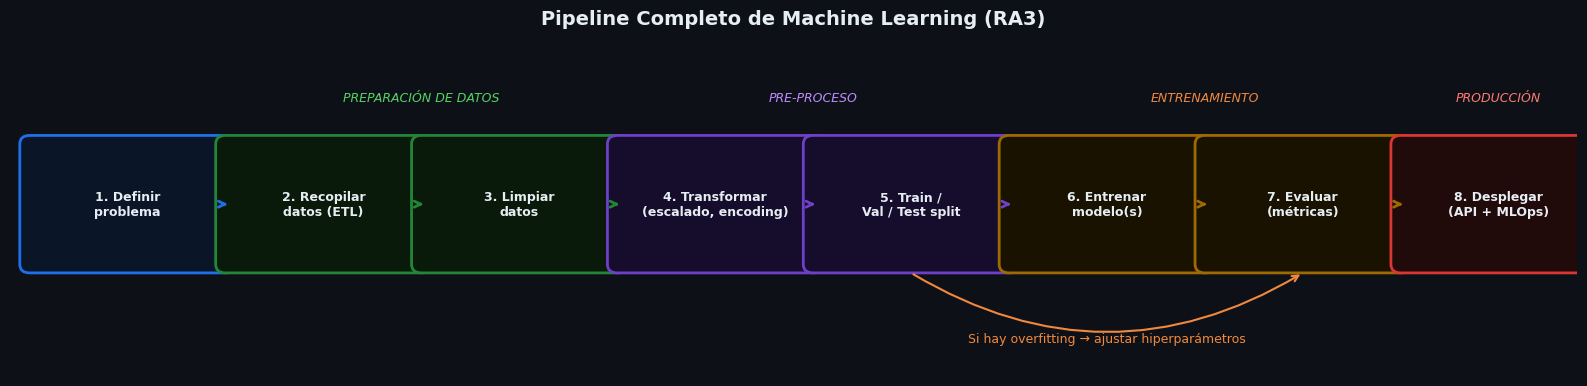

Guardado: 01_pipeline_ml.png


In [2]:
fig, ax = plt.subplots(figsize=(16, 4))
ax.set_xlim(0, 16)
ax.set_ylim(0, 4)
ax.axis('off')
ax.set_title('Pipeline Completo de Machine Learning (RA3)', color=WHITE, fontsize=14, fontweight='bold')

steps = [
    (1.2, '1. Definir\nproblema', '#1f6feb'),
    (3.2, '2. Recopilar\ndatos (ETL)', '#238636'),
    (5.2, '3. Limpiar\ndatos', '#238636'),
    (7.2, '4. Transformar\n(escalado, encoding)', '#6e40c9'),
    (9.2, '5. Train /\nVal / Test split', '#6e40c9'),
    (11.2, '6. Entrenar\nmodelo(s)', '#9e6a03'),
    (13.2, '7. Evaluar\n(métricas)', '#9e6a03'),
    (15.2, '8. Desplegar\n(API + MLOps)', '#da3633'),
]

colors_bg = ['#0a1628','#0a1a0a','#0a1a0a','#150d2b','#150d2b','#1a1200','#1a1200','#200a0a']

for (x, label, color), bgc in zip(steps, colors_bg):
    rect = mpatches.FancyBboxPatch((x-1.0, 1.3), 2.0, 1.4,
        boxstyle='round,pad=0.1', facecolor=bgc, edgecolor=color, linewidth=2)
    ax.add_patch(rect)
    ax.text(x, 2.0, label, ha='center', va='center', color=WHITE, fontsize=9, fontweight='bold')
    if x < 15.2:
        ax.annotate('', xy=(x+1.05, 2.0), xytext=(x+0.95, 2.0),
            arrowprops=dict(arrowstyle='->', color=color, lw=2))

# Feedback arrow (overfitting loop)
ax.annotate('', xy=(9.2, 1.2), xytext=(13.2, 1.2),
    arrowprops=dict(arrowstyle='<-', color=ORANGE, lw=1.5,
                   connectionstyle='arc3,rad=-0.3'))
ax.text(11.2, 0.4, 'Si hay overfitting → ajustar hiperparámetros', 
       ha='center', color=ORANGE, fontsize=9)

# Phase labels
ax.text(4.2, 3.2, 'PREPARACIÓN DE DATOS', ha='center', color='#56d364', fontsize=9, style='italic')
ax.text(8.2, 3.2, 'PRE-PROCESO', ha='center', color='#bc8cff', fontsize=9, style='italic')
ax.text(12.2, 3.2, 'ENTRENAMIENTO', ha='center', color='#f0883e', fontsize=9, style='italic')
ax.text(15.2, 3.2, 'PRODUCCIÓN', ha='center', color='#ff7b72', fontsize=9, style='italic')

plt.tight_layout()
plt.savefig(f'{OUT}/01_pipeline_ml.png', dpi=150, bbox_inches='tight', facecolor=DARK_BG)
plt.show()
print('Guardado: 01_pipeline_ml.png')

## Gráfico 2 — Escalado y normalización comparado

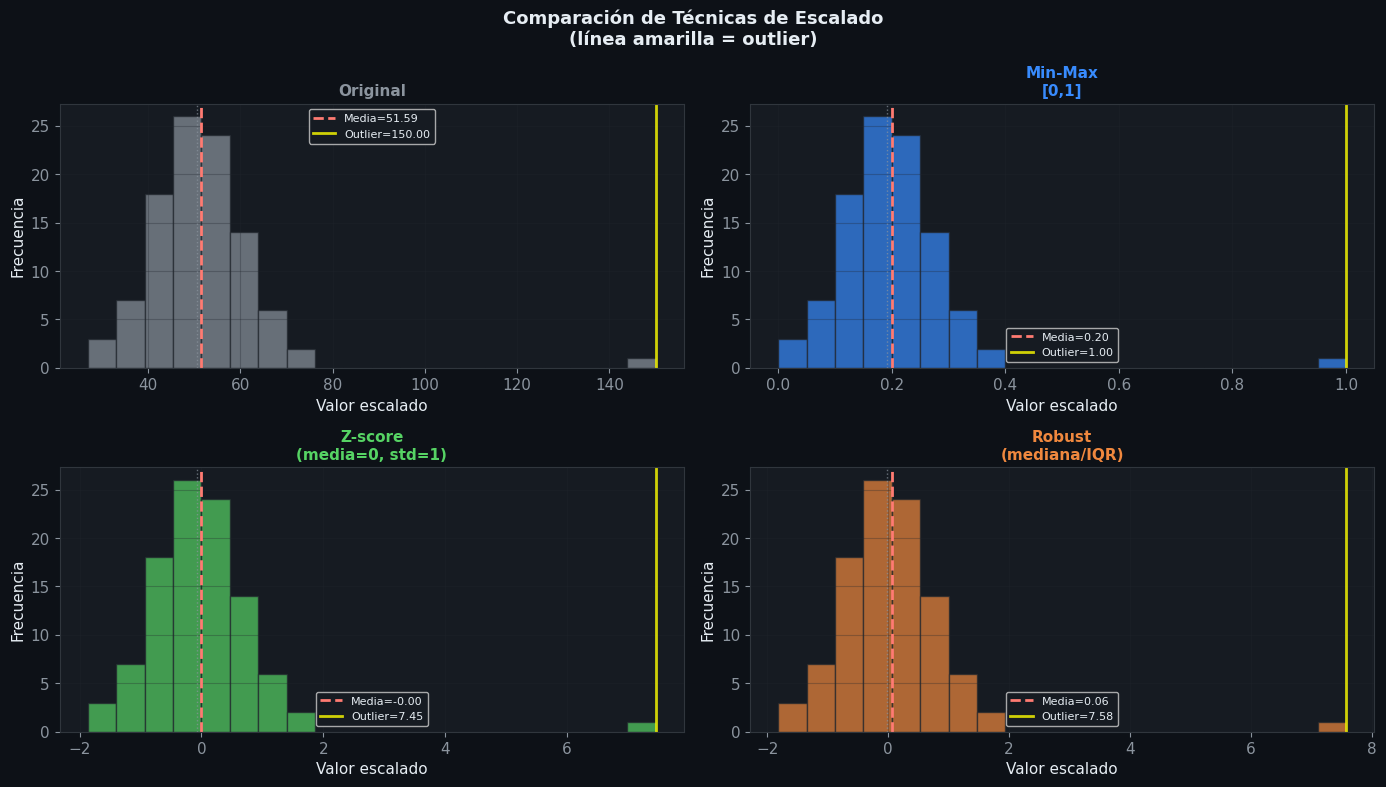

Guardado: 02_escalado.png


In [3]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

np.random.seed(1)
# Datos con outlier
data = np.concatenate([np.random.normal(50, 10, 100), [150]])
data = data.reshape(-1, 1)

scalers = [
    ('Original', data.flatten(), '#8b949e'),
    ('Min-Max\n[0,1]', MinMaxScaler().fit_transform(data).flatten(), BLUE),
    ('Z-score\n(media=0, std=1)', StandardScaler().fit_transform(data).flatten(), GREEN),
    ('Robust\n(mediana/IQR)', RobustScaler().fit_transform(data).flatten(), ORANGE),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for ax, (name, d, color) in zip(axes, scalers):
    ax.hist(d, bins=20, color=color, alpha=0.7, edgecolor='#21262d')
    ax.axvline(d.mean(), color=RED, linestyle='--', linewidth=2, label=f'Media={d.mean():.2f}')
    ax.axvline(d[:-1].mean(), color=GRAY, linestyle=':', linewidth=1, alpha=0.7)
    ax.set_title(name, color=color, fontweight='bold', fontsize=11)
    ax.legend(facecolor=PANEL_BG, labelcolor=WHITE, fontsize=9)
    ax.grid(True, alpha=0.3)
    
    # Annotate outlier effect
    outlier_scaled = d[-1]
    ax.axvline(outlier_scaled, color='yellow', linestyle='-', linewidth=2, alpha=0.8, label=f'Outlier={outlier_scaled:.2f}')
    ax.legend(facecolor=PANEL_BG, labelcolor=WHITE, fontsize=8)
    ax.set_xlabel('Valor escalado')
    ax.set_ylabel('Frecuencia')

plt.suptitle('Comparación de Técnicas de Escalado\n(línea amarilla = outlier)', 
            color=WHITE, fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUT}/02_escalado.png', dpi=150, bbox_inches='tight', facecolor=DARK_BG)
plt.show()
print('Guardado: 02_escalado.png')

## Gráfico 3 — Matriz de Confusión

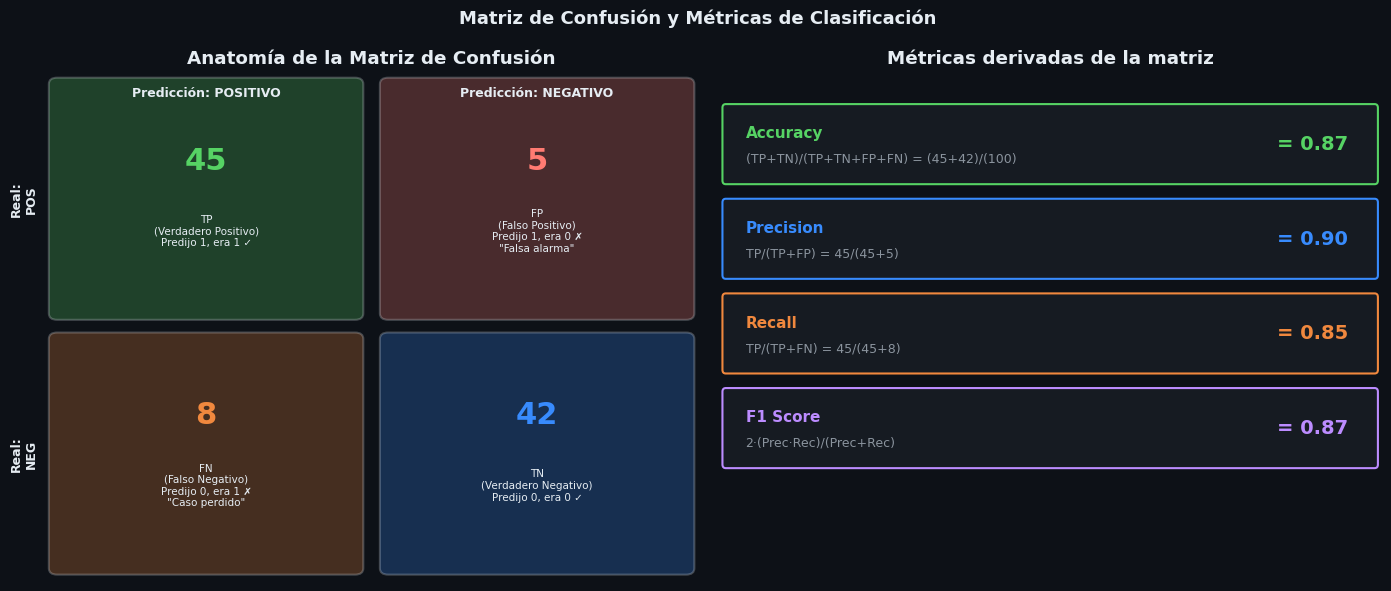

Guardado: 03_confusion_matrix.png


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left: anatomy of confusion matrix
ax = axes[0]
ax.set_xlim(0, 4)
ax.set_ylim(0, 4)
ax.axis('off')
ax.set_title('Anatomía de la Matriz de Confusión', color=WHITE, fontweight='bold')

cells = [
    (1, 3, 'TP\n(Verdadero Positivo)\nPredijo 1, era 1 ✓', GREEN,   '45'),
    (3, 3, 'FP\n(Falso Positivo)\nPredijo 1, era 0 ✗\n"Falsa alarma"', RED,    '5'),
    (1, 1, 'FN\n(Falso Negativo)\nPredijo 0, era 1 ✗\n"Caso perdido"', ORANGE,  '8'),
    (3, 1, 'TN\n(Verdadero Negativo)\nPredijo 0, era 0 ✓', BLUE,   '42'),
]

for x, y, text, color, count in cells:
    rect = mpatches.FancyBboxPatch((x-0.9, y-0.9), 1.8, 1.8,
        boxstyle='round,pad=0.05', facecolor=color, edgecolor=WHITE, linewidth=1.5, alpha=0.25)
    ax.add_patch(rect)
    ax.text(x, y+0.3, count, ha='center', va='center', color=color, fontsize=22, fontweight='bold')
    ax.text(x, y-0.25, text, ha='center', va='center', color=WHITE, fontsize=7.5)

ax.text(1, 3.8, 'Predicción: POSITIVO', ha='center', color=WHITE, fontsize=9, fontweight='bold')
ax.text(3, 3.8, 'Predicción: NEGATIVO', ha='center', color=WHITE, fontsize=9, fontweight='bold')
ax.text(-0.1, 3, 'Real:\nPOS', ha='center', va='center', color=WHITE, fontsize=9, fontweight='bold', rotation=90)
ax.text(-0.1, 1, 'Real:\nNEG', ha='center', va='center', color=WHITE, fontsize=9, fontweight='bold', rotation=90)

# Right: metrics derived
ax = axes[1]
ax.set_xlim(0, 10)
ax.set_ylim(0, 7)
ax.axis('off')
ax.set_title('Métricas derivadas de la matriz', color=WHITE, fontweight='bold')

TP, FP, FN, TN = 45, 5, 8, 42
metrics = [
    ('Accuracy',  f'(TP+TN)/(TP+TN+FP+FN) = ({TP}+{TN})/({TP+TN+FP+FN})', f'= {(TP+TN)/(TP+TN+FP+FN):.2f}', GREEN),
    ('Precision', f'TP/(TP+FP) = {TP}/({TP}+{FP})',                         f'= {TP/(TP+FP):.2f}', BLUE),
    ('Recall',    f'TP/(TP+FN) = {TP}/({TP}+{FN})',                         f'= {TP/(TP+FN):.2f}', ORANGE),
    ('F1 Score',  f'2·(Prec·Rec)/(Prec+Rec)',                                f'= {2*(TP/(TP+FP))*(TP/(TP+FN))/((TP/(TP+FP))+(TP/(TP+FN))):.2f}', PURPLE),
]

for i, (name, formula, result, color) in enumerate(metrics):
    y = 6 - i * 1.3
    rect = mpatches.FancyBboxPatch((0.1, y-0.5), 9.8, 1.0,
        boxstyle='round,pad=0.05', facecolor='#161b22', edgecolor=color, linewidth=1.5)
    ax.add_patch(rect)
    ax.text(0.4, y+0.15, name, ha='left', va='center', color=color, fontsize=11, fontweight='bold')
    ax.text(0.4, y-0.2, formula, ha='left', va='center', color=GRAY, fontsize=9)
    ax.text(9.5, y, result, ha='right', va='center', color=color, fontsize=14, fontweight='bold')

plt.suptitle('Matriz de Confusión y Métricas de Clasificación', color=WHITE, fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUT}/03_confusion_matrix.png', dpi=150, bbox_inches='tight', facecolor=DARK_BG)
plt.show()
print('Guardado: 03_confusion_matrix.png')

## Gráfico 4 — Curva ROC y AUC

/tmp/ipykernel_5682/702874684.py:54: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


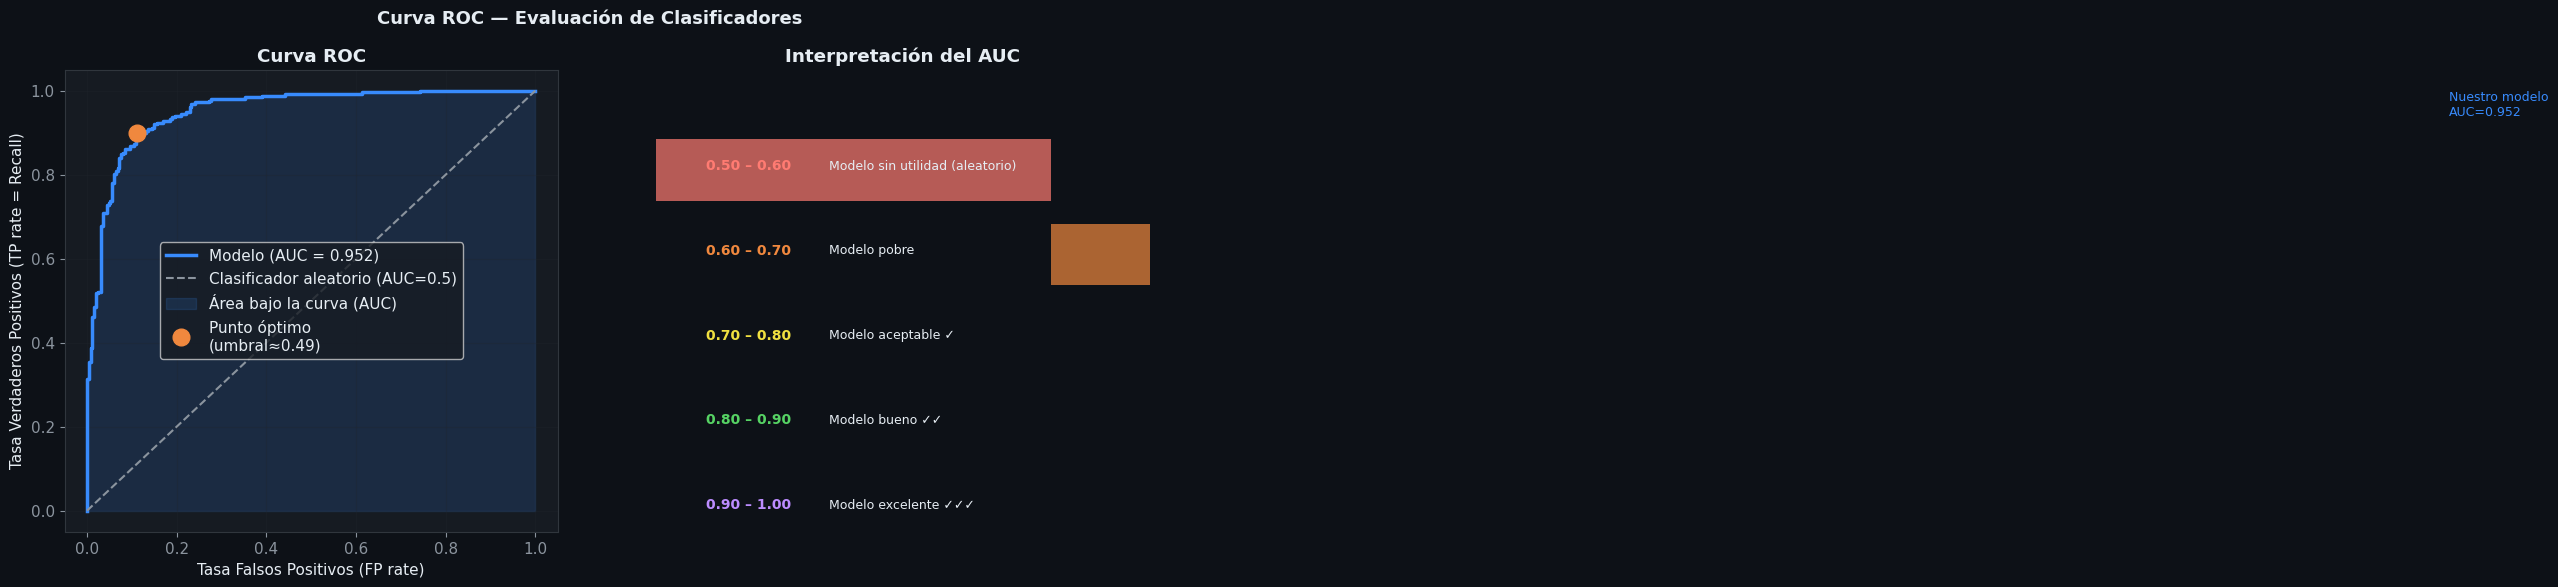

Guardado: 04_roc_auc.png


In [5]:
X_roc, y_roc = make_classification(n_samples=500, n_features=5, random_state=42)
clf = LogisticRegression().fit(X_roc, y_roc)
probs = clf.predict_proba(X_roc)[:, 1]

fpr, tpr, thresholds = roc_curve(y_roc, probs)
roc_auc = auc(fpr, tpr)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ROC curve
ax = axes[0]
ax.plot(fpr, tpr, color=BLUE, linewidth=2.5, label=f'Modelo (AUC = {roc_auc:.3f})')
ax.plot([0,1],[0,1], color=GRAY, linestyle='--', linewidth=1.5, label='Clasificador aleatorio (AUC=0.5)')
ax.fill_between(fpr, tpr, alpha=0.15, color=BLUE, label='Área bajo la curva (AUC)')

# Mark operating points
idx_opt = np.argmax(tpr - fpr)
ax.plot(fpr[idx_opt], tpr[idx_opt], 'o', color=ORANGE, markersize=12, zorder=5,
       label=f'Punto óptimo\n(umbral≈{thresholds[idx_opt]:.2f})')

ax.set_xlabel('Tasa Falsos Positivos (FP rate)')
ax.set_ylabel('Tasa Verdaderos Positivos (TP rate = Recall)')
ax.set_title('Curva ROC', color=WHITE, fontweight='bold')
ax.legend(facecolor=PANEL_BG, labelcolor=WHITE)
ax.grid(True, alpha=0.3)

# AUC interpretation guide
ax = axes[1]
ax.set_xlim(0, 10)
ax.set_ylim(0, 6)
ax.axis('off')
ax.set_title('Interpretación del AUC', color=WHITE, fontweight='bold')

ranges = [
    (0.5, 0.6, '0.50 – 0.60', 'Modelo sin utilidad (aleatorio)',   RED),
    (0.6, 0.7, '0.60 – 0.70', 'Modelo pobre',                      ORANGE),
    (0.7, 0.8, '0.70 – 0.80', 'Modelo aceptable ✓',                '#f0e040'),
    (0.8, 0.9, '0.80 – 0.90', 'Modelo bueno ✓✓',                   GREEN),
    (0.9, 1.0, '0.90 – 1.00', 'Modelo excelente ✓✓✓',              PURPLE),
]

for i, (lo, hi, rng, desc, color) in enumerate(reversed(ranges)):
    y = i * 1.1 + 0.3
    bar_w = (hi - lo) * 80
    ax.barh(y, bar_w, left=(lo-0.5)*80, height=0.8, color=color, alpha=0.7)
    ax.text(1, y+0.05, rng, va='center', color=color, fontsize=10, fontweight='bold')
    ax.text(3.5, y+0.05, desc, va='center', color=WHITE, fontsize=9)

# Mark current model
ax.axvline((roc_auc-0.5)*80, color=BLUE, linewidth=3, linestyle='--')
ax.text((roc_auc-0.5)*80+0.2, 5.4, f'Nuestro modelo\nAUC={roc_auc:.3f}', color=BLUE, fontsize=9)

plt.suptitle('Curva ROC — Evaluación de Clasificadores', color=WHITE, fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUT}/04_roc_auc.png', dpi=150, bbox_inches='tight', facecolor=DARK_BG)
plt.show()
print('Guardado: 04_roc_auc.png')

## Gráfico 5 — Regularización L1 vs L2 (efecto sobre pesos)

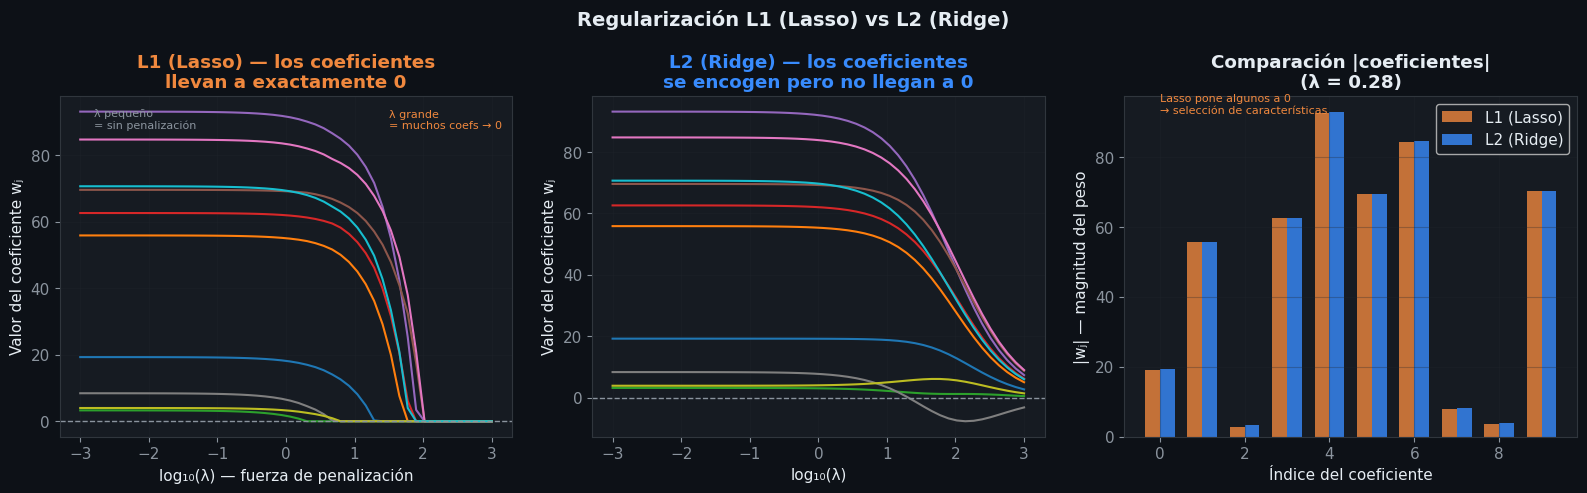

Guardado: 05_regularizacion.png


In [6]:
from sklearn.linear_model import Lasso, Ridge
from sklearn.datasets import make_regression

X_reg, y_reg = make_regression(n_samples=100, n_features=10, noise=15, random_state=42)
alphas = np.logspace(-3, 3, 50)

lasso_coefs = []
ridge_coefs = []
for a in alphas:
    lasso_coefs.append(Lasso(alpha=a, max_iter=5000).fit(X_reg, y_reg).coef_)
    ridge_coefs.append(Ridge(alpha=a).fit(X_reg, y_reg).coef_)

lasso_coefs = np.array(lasso_coefs)
ridge_coefs = np.array(ridge_coefs)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# L1 path
ax = axes[0]
for j in range(10):
    ax.plot(np.log10(alphas), lasso_coefs[:, j], linewidth=1.5)
ax.axhline(0, color=GRAY, linestyle='--', linewidth=1)
ax.set_xlabel('log₁₀(λ) — fuerza de penalización')
ax.set_ylabel('Valor del coeficiente wⱼ')
ax.set_title('L1 (Lasso) — los coeficientes\nllevan a exactamente 0', color=ORANGE, fontweight='bold')
ax.text(-2.8, ax.get_ylim()[1]*0.9, 'λ pequeño\n= sin penalización', color=GRAY, fontsize=8)
ax.text(1.5, ax.get_ylim()[1]*0.9, 'λ grande\n= muchos coefs → 0', color=ORANGE, fontsize=8)
ax.grid(True, alpha=0.3)

# L2 path
ax = axes[1]
for j in range(10):
    ax.plot(np.log10(alphas), ridge_coefs[:, j], linewidth=1.5)
ax.axhline(0, color=GRAY, linestyle='--', linewidth=1)
ax.set_xlabel('log₁₀(λ)')
ax.set_ylabel('Valor del coeficiente wⱼ')
ax.set_title('L2 (Ridge) — los coeficientes\nse encogen pero no llegan a 0', color=BLUE, fontweight='bold')
ax.grid(True, alpha=0.3)

# Comparison at a fixed alpha
ax = axes[2]
a_idx = 20  # middle alpha
x_idx = np.arange(10)
w = 0.35
ax.bar(x_idx - w/2, np.abs(lasso_coefs[a_idx]), w, color=ORANGE, alpha=0.8, label='L1 (Lasso)')
ax.bar(x_idx + w/2, np.abs(ridge_coefs[a_idx]), w, color=BLUE, alpha=0.8, label='L2 (Ridge)')
ax.set_xlabel('Índice del coeficiente')
ax.set_ylabel('|wⱼ| — magnitud del peso')
ax.set_title(f'Comparación |coeficientes|\n(λ = {alphas[a_idx]:.2f})', color=WHITE, fontweight='bold')
ax.legend(facecolor=PANEL_BG, labelcolor=WHITE)
ax.grid(True, alpha=0.3)
ax.text(0, ax.get_ylim()[1]*0.95, 'Lasso pone algunos a 0\n→ selección de características', 
       color=ORANGE, fontsize=8)

plt.suptitle('Regularización L1 (Lasso) vs L2 (Ridge)', color=WHITE, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUT}/05_regularizacion.png', dpi=150, bbox_inches='tight', facecolor=DARK_BG)
plt.show()
print('Guardado: 05_regularizacion.png')

## Gráfico 6 — Cross-Validation (K-Fold)

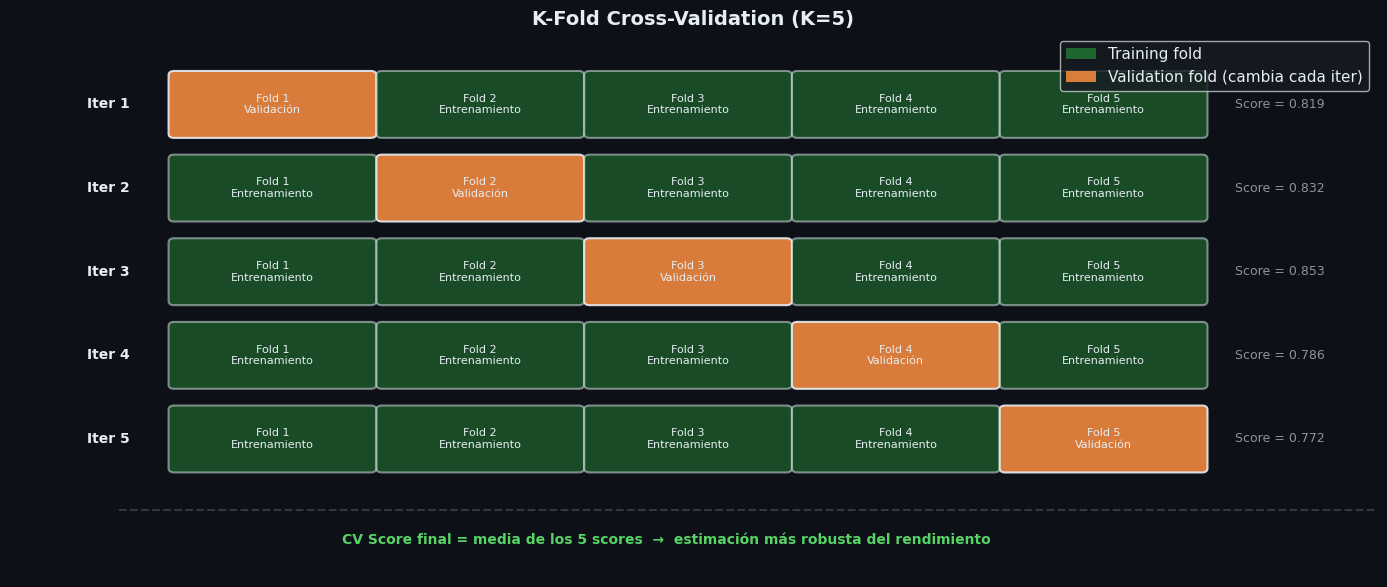

Guardado: 06_cross_validation.png


In [7]:
fig, ax = plt.subplots(figsize=(14, 6))
ax.set_xlim(-0.5, 12)
ax.set_ylim(-0.5, 6)
ax.axis('off')
ax.set_title('K-Fold Cross-Validation (K=5)', color=WHITE, fontsize=14, fontweight='bold')

K = 5
n_folds = 5
fold_w = 1.8
fold_h = 0.7
start_x = 1.0

for fold_iter in range(K):
    y_pos = K - fold_iter - 0.2
    ax.text(0.2, y_pos + fold_h/2, f'Iter {fold_iter+1}', va='center', color=WHITE, 
           fontsize=10, fontweight='bold')
    for j in range(n_folds):
        x = start_x + j * (fold_w + 0.1)
        is_val = (j == fold_iter)
        color = ORANGE if is_val else '#238636'
        alpha = 0.9 if is_val else 0.5
        label = 'Validación' if is_val else 'Entrenamiento'
        rect = mpatches.FancyBboxPatch((x, y_pos), fold_w, fold_h,
            boxstyle='round,pad=0.05', facecolor=color, edgecolor=WHITE, 
            linewidth=1.5, alpha=alpha)
        ax.add_patch(rect)
        ax.text(x + fold_w/2, y_pos + fold_h/2, f'Fold {j+1}\n{label}', 
               ha='center', va='center', color=WHITE, fontsize=8)
    
    # Score annotation
    score = 0.82 + np.random.uniform(-0.05, 0.05)
    ax.text(start_x + n_folds*(fold_w+0.1) + 0.2, y_pos + fold_h/2, 
           f'Score = {score:.3f}', va='center', color=GRAY, fontsize=9)

# Final average
ax.axhline(0.3, color=GRAY, linestyle='--', alpha=0.3, xmin=0.08)
ax.text(5.5, -0.1, 'CV Score final = media de los 5 scores  →  estimación más robusta del rendimiento',
       ha='center', color=GREEN, fontsize=10, fontweight='bold')

# Legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#238636', alpha=0.7, label='Training fold'),
                   Patch(facecolor=ORANGE, alpha=0.9, label='Validation fold (cambia cada iter)')]
ax.legend(handles=legend_elements, loc='upper right', facecolor=PANEL_BG, labelcolor=WHITE)

plt.tight_layout()
plt.savefig(f'{OUT}/06_cross_validation.png', dpi=150, bbox_inches='tight', facecolor=DARK_BG)
plt.show()
print('Guardado: 06_cross_validation.png')

## Gráfico 7 — Train / Validation / Test split

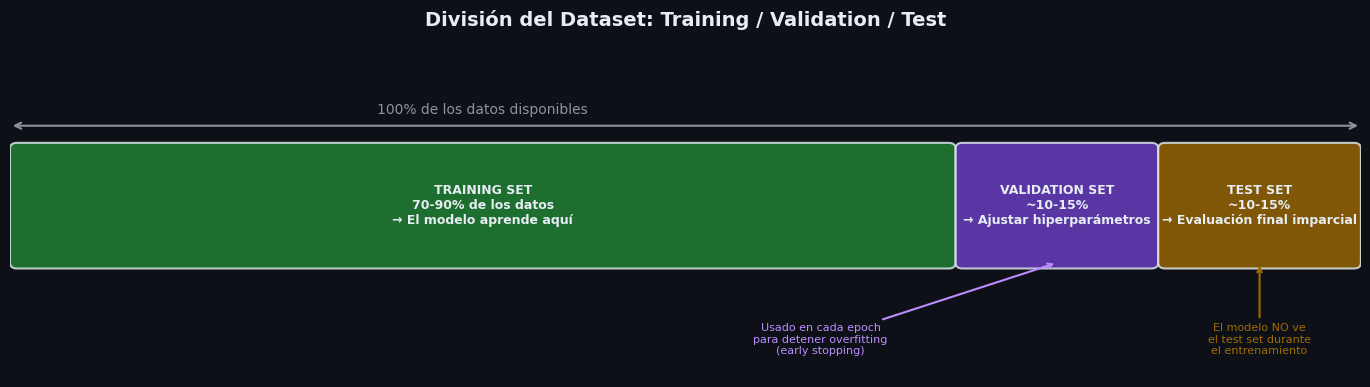

Guardado: 07_train_val_test.png


In [8]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.set_xlim(0, 10)
ax.set_ylim(0, 3)
ax.axis('off')
ax.set_title('División del Dataset: Training / Validation / Test', color=WHITE, fontsize=14, fontweight='bold')

splits = [
    (0, 7, '#238636', 'TRAINING SET\n70-90% de los datos\n→ El modelo aprende aquí'),
    (7, 8.5, '#6e40c9', 'VALIDATION SET\n~10-15%\n→ Ajustar hiperparámetros'),
    (8.5, 10, '#9e6a03', 'TEST SET\n~10-15%\n→ Evaluación final imparcial'),
]

for x0, x1, color, label in splits:
    rect = mpatches.FancyBboxPatch((x0+0.05, 1.0), x1-x0-0.1, 1.0,
        boxstyle='round,pad=0.05', facecolor=color, edgecolor=WHITE, linewidth=1.5, alpha=0.8)
    ax.add_patch(rect)
    ax.text((x0+x1)/2, 1.5, label, ha='center', va='center', color=WHITE, fontsize=9, fontweight='bold')

# Annotations
ax.annotate('El modelo NO ve\nel test set durante\nel entrenamiento', 
           xy=(9.25, 1.0), xytext=(9.25, 0.2),
           arrowprops=dict(arrowstyle='->', color='#9e6a03', lw=1.5),
           ha='center', color='#9e6a03', fontsize=8)

ax.annotate('Usado en cada epoch\npara detener overfitting\n(early stopping)', 
           xy=(7.75, 1.0), xytext=(6.0, 0.2),
           arrowprops=dict(arrowstyle='->', color='#bc8cff', lw=1.5),
           ha='center', color='#bc8cff', fontsize=8)

ax.text(3.5, 2.3, '100% de los datos disponibles', ha='center', color=GRAY, fontsize=10)
ax.annotate('', xy=(0, 2.2), xytext=(10, 2.2),
   arrowprops=dict(arrowstyle='<->', color=GRAY, lw=1.5))

plt.tight_layout()
plt.savefig(f'{OUT}/07_train_val_test.png', dpi=150, bbox_inches='tight', facecolor=DARK_BG)
plt.show()
print('Guardado: 07_train_val_test.png')